# Sketch2Future · Approach 2 — SD 1.5 LoRA Training (notebook)

**Purpose:** To fine-tune a **style LoRA** on public **Axis-V1 photographs** dataset and matching `.txt` captions; then load those LoRA weights into **the same Stable Diffusion v1.5 + ControlNet Scribble + text-prompt pipeline as Approach 1**.

### Agreed research design

- **Approach 1:** sketch + prompt → SD 1.5 + ControlNet Scribble or Canny → baseline image.
- **Approach 2:** same sketch + same core prompt → SD 1.5 + ControlNet Scribble **with trained LoRA** → comparison image.
- LoRA learns **appearance/style** from image+caption pairs; **ControlNet** remains responsible for sketch conditioning.
- We do **not** train ControlNet, and sketches dataset are **not required** for LoRA training.

### The workflow in this notebook
1. Check GPU and locate your Kaggle-uploaded dataset folder or ZIP.
2. Validate matching `image.jpg` + `image.txt` pairs and preview originals.
3. Create a balanced sample and inspect **approximate** bucket crops **without modifying the source images**.
4. Create a training split plus holdout and generate `dataset_config.toml`.
5. Install **pinned kohya-ss/sd-scripts v0.12.3** and train a **U-Net-only rank-16 LoRA** with aspect-ratio bucketing.
6. Save `.safetensors`, logs, exact settings and download the archive.
7. **Test:** load the trained LoRA with SD 1.5 + Scribble ControlNet and compare results on one **held-out sketch**, using the same prompt and seed.


References: [sd-scripts release](https://github.com/kohya-ss/sd-scripts/releases/tag/v0.12.3) · [dataset configuration](https://github.com/kohya-ss/sd-scripts/blob/main/docs/config_README-en.md) · [training guide](https://github.com/kohya-ss/sd-scripts/blob/main/docs/train_network.md) · [Diffusers LoRA loader](https://huggingface.co/docs/diffusers/api/loaders/lora)

## Kaggle runtime and GPU check

We use **Accelerator → GPU T4 x2**.

In [1]:
import os, sys, json, csv, re, math, hashlib, random, shutil, subprocess, zipfile, time, gc
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import importlib.metadata as md

import torch
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageFile
import matplotlib.pyplot as plt
from IPython.display import display

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU detected. In Kaggle notebook Settings, enable a GPU accelerator.')
print('GPU count:', torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f'GPU {i}: {torch.cuda.get_device_name(i)}')
print('CUDA runtime reported by torch:', torch.version.cuda)
print('GPU 0 memory (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))


Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
CUDA runtime reported by torch: 13.0
GPU 0 memory (GiB): 14.6


## Training Configuration

We upload the folder/ZIP containing our selected Axis-V1 image/caption pairs to the Kaggle notebook using **Add Input**. Sample file type in it (filename & caption), e.g `cinematic_066.jpg` and `cinematic_066.txt` .

The public dataset used is the refine-axis/axis-v1_1k and it spans varied subjects and aesthetics so we did not lock style by using trigger words.

**Style token:** `ADD_STYLE_TRIGGER`= false  because we want the LoRA to learn general sketch-to-image translation without locking into a single style token. Labelling visually inconsistent images as one style can reduce usefulness of the LoRA.

In [2]:
# SETTINGS

DATASET_SOURCE = '/kaggle/input/datasets/gabswoch/sketch2imagedata/sketch_trainingData'
MAX_TRAINING_CANDIDATES = 623  # use up to this many eligible image-caption pairs before holdout
HOLDOUT_FRACTION = 0.10
MIN_SHORT_EDGE = 512           # flag/skip smaller source files to avoid unnecessary upscaling
MIN_CAPTION_LENGTH = 12
SEED = 42

# Kept False because refine-axis/axis-v1_1k spans varied subjects and aesthetics;
ADD_STYLE_TRIGGER = False
STYLE_TRIGGER = 'sketch2future style'

ROOT = Path('/kaggle/working/sketch2future_lora')
SOURCE_TMP = ROOT / 'extracted_source'
TRAIN_IMAGES = ROOT / 'train_images'
HOLDOUT_IMAGES = ROOT / 'holdout_images'
CONFIG_DIR = ROOT / 'config'
MODEL_DIR = ROOT / 'lora_weights'
PREVIEWS_DIR = ROOT / 'previews'
LOG_DIR = ROOT / 'logs'
for d in [ROOT, SOURCE_TMP, TRAIN_IMAGES, HOLDOUT_IMAGES, CONFIG_DIR, MODEL_DIR, PREVIEWS_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
print('Working directory:', ROOT)

Working directory: /kaggle/working/sketch2future_lora


## Loading the dataset

We had set the `DATASET_SOURCE` in the previous cell. For reproductivity, if the dataset is different, just input a different source path

In [3]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.webp'}


source = Path(DATASET_SOURCE)

if not source.exists():
    raise FileNotFoundError(f"Dataset path not found: {source}")

# Optional: quick sanity check to verify image/text pairs in the folder
if source.is_dir():
    images = [f for f in source.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_SUFFIXES]
    captions = {f.stem.casefold() for f in source.iterdir() if f.is_file() and f.suffix.lower() == '.txt'}
    paired_count = sum(img.stem.casefold() in captions for img in images)
    print(f"Loaded dataset: {source} ({paired_count} image-text pairs found)")
else:
    print(f"Loaded archive: {source}")

Loaded dataset: /kaggle/input/datasets/gabswoch/sketch2imagedata/sketch_trainingData (621 image-text pairs found)


## Access dataset files (ZIP or folder), then audit image/caption pairs

Validating the ZIP archive content because it may contain one or more subfolders, corrupt images, missing captions, blank captions and exact duplicate image contents so they can be excluded.

In [4]:
# the uploaded unzipped dataset folder
if not source.is_dir():
    raise ValueError(f"Expected a dataset folder, but got: {source}")

# Gathering all images and map their matching .txt caption files
all_images = sorted(
    p for p in source.rglob('*') 
    if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
)

caption_map = {
    (p.parent.resolve(), p.stem.casefold()): p
    for p in source.rglob('*.txt')
    if p.is_file()
}

# validate each image-caption pair
valid_rows = []
rejected_rows = []
seen_hashes = set()

for img_path in all_images:
    lookup_key = (img_path.parent.resolve(), img_path.stem.casefold())
    txt_path = caption_map.get(lookup_key)

    if not txt_path:
        rejected_rows.append({'path': str(img_path), 'reason': 'Missing matching .txt file'})
        continue

    try:
        # checking the caption length
        caption = txt_path.read_text(encoding='utf-8-sig').strip()
        if len(caption) < MIN_CAPTION_LENGTH:
            raise ValueError('Caption is blank or too short')

        # checking the image integrity and dimensions
        with Image.open(img_path) as img:
            img = ImageOps.exif_transpose(img)
            img.load() 
            width, height = img.size

        if min(width, height) < MIN_SHORT_EDGE:
            raise ValueError(f'Short edge is under {MIN_SHORT_EDGE}px')

        # checking for exact duplicates
        file_hash = hashlib.sha256(img_path.read_bytes()).hexdigest()
        if file_hash in seen_hashes:
            raise ValueError('Exact duplicate image')
        seen_hashes.add(file_hash)

        # save valid entry
        valid_rows.append({
            'image_path': str(img_path),
            'caption_file': str(txt_path),
            'caption': caption,
            'category': img_path.stem.split('_')[0].casefold(),
            'width': width,
            'height': height,
            'aspect': round(width / height, 4),
            'sha256': file_hash,
        })

    except Exception as err:
        rejected_rows.append({'path': str(img_path), 'reason': str(err)})

# the audit logs and display summary
audit = pd.DataFrame(valid_rows)
reject_df = pd.DataFrame(rejected_rows)

audit.to_csv(ROOT / 'eligible_audit.csv', index=False)
reject_df.to_csv(ROOT / 'rejected_audit.csv', index=False)

print(f"Found {len(all_images)} images | Valid pairs: {len(audit)} | Excluded: {len(reject_df)}")

if audit.empty:
    display(reject_df.head(25))
    raise RuntimeError("No valid training pairs found. Check your folder path and quality thresholds.")

print("\nCategory counts (inferred from filename prefixes):")
display(audit['category'].value_counts().rename('count').to_frame())

print("\nImage dimensions & aspect ratio summary:")
display(audit[['width', 'height', 'aspect']].describe().round(2))

if not reject_df.empty:
    print("\nSample of excluded files:")
    display(reject_df.head(15))

Found 623 images | Valid pairs: 618 | Excluded: 5

Category counts (inferred from filename prefixes):


,count
category,
nature,120
night,107
human,80
architecture,68
cinematic,68
animals,65
vehicles,64
robotics,46



Image dimensions & aspect ratio summary:


,width,height,aspect
count,618.00,618.00,618.00
mean,4200.08,4687.57,0.96
std,1351.23,1431.04,0.39
min,1665.00,1458.00,0.56
25%,3264.25,3671.25,0.67
50%,4000.00,4504.50,0.75
75%,5184.00,6000.00,1.50
max,9126.00,9504.00,2.07



Sample of excluded files:


,path,reason
0,/kaggle/input/datasets/gabswoch/sketch2imageda...,Exact duplicate image
1,/kaggle/input/datasets/gabswoch/sketch2imageda...,Missing matching .txt file
2,/kaggle/input/datasets/gabswoch/sketch2imageda...,Exact duplicate image
3,/kaggle/input/datasets/gabswoch/sketch2imageda...,Exact duplicate image
4,/kaggle/input/datasets/gabswoch/sketch2imageda...,Missing matching .txt file


## Preview actual training candidates **before selecting them**

This displays the original images at thumbnail size. It does not resize your source files or change captions.

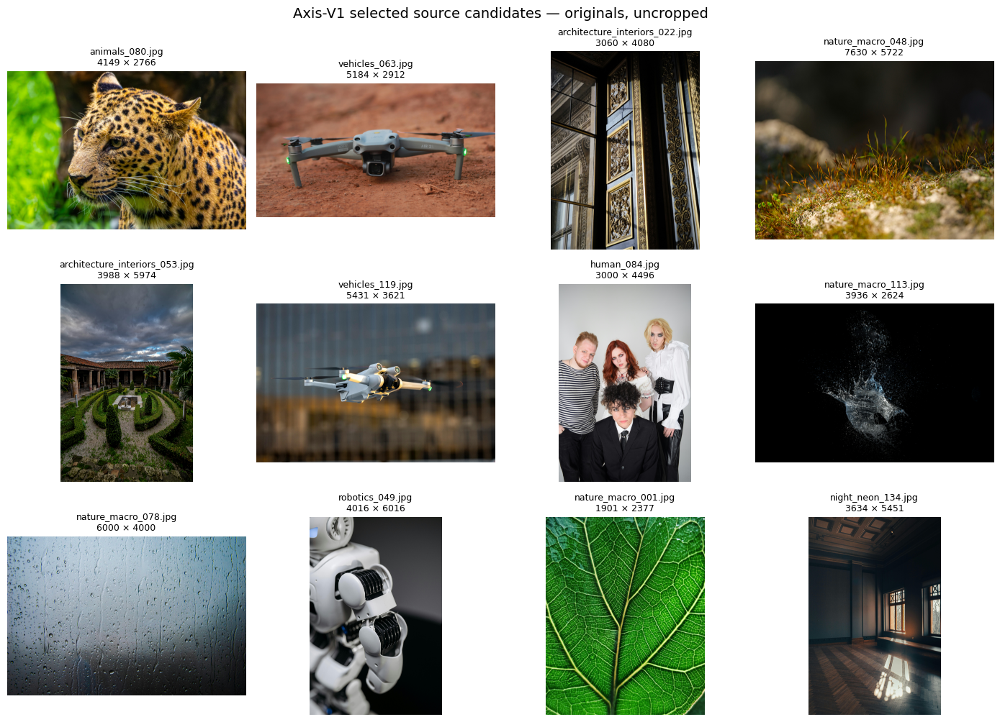

Example original captions:

 animals_080.jpg 
 The image features a close-up of a leopard's face, with its eyes wide open and staring directly at the camera. The leopard's fur is a mix of brown and black, with a distinctive pattern that sets it apart from other big cats. The leopard's face is adorned with a prominent nose, and its eyes are positioned on the sides of its head, giving it a unique

 vehicles_063.jpg 
 The image features a close-up view of a camera mounted on a drone, which is sitting on a dirt ground. The drone is equipped with a camera, and it appears to be a small, lightweight device. The camera is positioned in the center of the drone, capturing the scene from a unique perspective. The dirt ground provides a natural backdrop for the drone, an

 architecture_interiors_022.jpg 
 The image features a large, ornate building with a gold and black color scheme. The building's facade is adorned with intricate carvings and decorative elements, creating a visually striking scen

In [5]:
def contact_sheet(frame, n=12, cols=4, title='Original source images'):
    if len(frame) == 0: return
    shown = frame.sample(n=min(n, len(frame)), random_state=SEED)
    nrows = math.ceil(len(shown) / cols)
    fig, axes = plt.subplots(nrows, cols, figsize=(cols*3.5, nrows*3.4))
    axes = np.array(axes, dtype=object).reshape(-1)
    
    for ax, (_, record) in zip(axes, shown.iterrows()):
        with Image.open(record['image_path']) as im:
            img = ImageOps.exif_transpose(im).convert('RGB')
            ax.imshow(img)
        ax.set_title(f"{Path(record['image_path']).name}\n{record['width']} × {record['height']}", fontsize=9)
        ax.axis('off')
        
    for ax in axes[len(shown):]: ax.axis('off')
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

contact_sheet(audit, 12, title='Axis-V1 selected source candidates — originals, uncropped')
print('Example original captions:')

for _, row in audit.sample(n=min(5,len(audit)), random_state=SEED).iterrows():
    print('\n', Path(row['image_path']).name, '\n', row['caption'][:350])

## Preview Aspect-Ratio Bucketing & Cropping

During training, SD 1.5 uses **aspect-ratio bucketing** (`enable_bucket = true`, `bucket_no_upscale = true`) around a `512×512` base area. While this avoids squashing images into squares, it center-crops any edges that don't quite fit a bucket.

Below is an approximation of how the images will be resized and cropped (note: `sd-scripts` handles exact pixel rounding slightly differently internally). Check the previews to make sure important sketch details aren't getting cut off—your original dataset files will remain untouched.

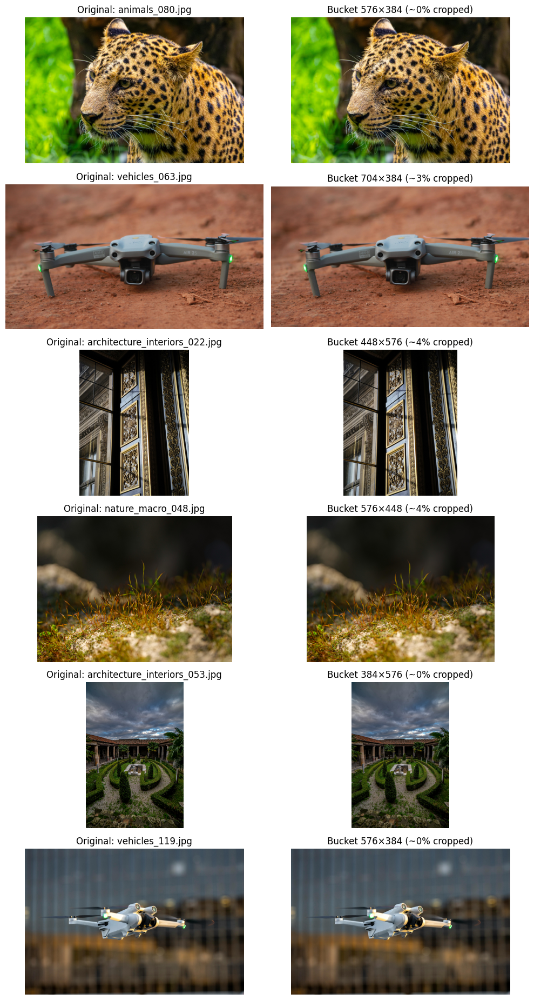

Images with >10% estimated crop loss: 0


,image_path,width,height,approx_bucket_width,approx_bucket_height,estimated_crop_fraction
46,/kaggle/input/datasets/gabswoch/sketch2imageda...,2400,2898,448,576,0.060833
173,/kaggle/input/datasets/gabswoch/sketch2imageda...,4633,2242,704,320,0.060701
333,/kaggle/input/datasets/gabswoch/sketch2imageda...,1691,2048,448,576,0.058020
190,/kaggle/input/datasets/gabswoch/sketch2imageda...,4521,2874,576,384,0.046450
198,/kaggle/input/datasets/gabswoch/sketch2imageda...,3870,5277,448,640,0.045504
192,/kaggle/input/datasets/gabswoch/sketch2imageda...,7950,4969,640,384,0.040048
75,/kaggle/input/datasets/gabswoch/sketch2imageda...,3062,4899,384,640,0.040039
193,/kaggle/input/datasets/gabswoch/sketch2imageda...,7699,4812,640,384,0.040025
56,/kaggle/input/datasets/gabswoch/sketch2imageda...,2560,4000,384,576,0.040000
335,/kaggle/input/datasets/gabswoch/sketch2imageda...,3942,2874,640,448,0.039875


In [6]:
# SD 1.5 bucket sizes (multiples of 64 near 512x512 pixel area)
BUCKET_STEP = 64
MIN_BUCKET, MAX_BUCKET = 256, 768
TARGET_PIXELS = 512 * 512

BUCKET_CANDIDATES = [
    (w, h)
    for w in range(MIN_BUCKET, MAX_BUCKET + 1, BUCKET_STEP)
    for h in range(MIN_BUCKET, MAX_BUCKET + 1, BUCKET_STEP)
    if 0.82 * TARGET_PIXELS <= (w * h) <= 1.12 * TARGET_PIXELS
]


def get_closest_bucket(width, height):
    """Find the closest SD 1.5 bucket size matching the image's aspect ratio."""
    aspect_ratio = width / height
    return min(
        BUCKET_CANDIDATES,
        key=lambda b: abs(math.log((b[0] / b[1]) / aspect_ratio)) * 2
                      + abs(math.log((b[0] * b[1]) / TARGET_PIXELS)) * 0.18
    )


def estimate_crop_loss(width, height, bucket_w, bucket_h):
    """Estimate the fraction of the image lost to center-cropping."""
    src_ratio = width / height
    dst_ratio = bucket_w / bucket_h
    return max(0.0, 1.0 - min(src_ratio / dst_ratio, dst_ratio / src_ratio))


# compute bucket estimates for the entire audit DataFrame
buckets = [get_closest_bucket(w, h) for w, h in zip(audit['width'], audit['height'])]
audit['approx_bucket_width'] = [b[0] for b in buckets]
audit['approx_bucket_height'] = [b[1] for b in buckets]
audit['estimated_crop_fraction'] = [
    estimate_crop_loss(w, h, bw, bh)
    for w, h, (bw, bh) in zip(audit['width'], audit['height'], buckets)
]

# checking 6 random images side-by-side (Original vs. Bucket-Cropped)
samples = audit.sample(n=min(6, len(audit)), random_state=SEED)
fig, axes = plt.subplots(len(samples), 2, figsize=(10, 3.1 * len(samples)))
axes = np.array(axes, dtype=object).reshape(len(samples), 2)

for idx, (_, row) in enumerate(samples.iterrows()):
    img_path = Path(row['image_path'])
    bucket = (int(row['approx_bucket_width']), int(row['approx_bucket_height']))
    crop_loss = row['estimated_crop_fraction']

    with Image.open(img_path) as im:
        original = ImageOps.exif_transpose(im).convert('RGB')
    cropped = ImageOps.fit(original, bucket, method=Image.Resampling.LANCZOS, centering=(0.5, 0.5))

    axes[idx, 0].imshow(original)
    axes[idx, 0].set_title(f"Original: {img_path.name}")
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(cropped)
    axes[idx, 1].set_title(f"Bucket {bucket[0]}×{bucket[1]} (~{crop_loss:.0%} cropped)")
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

# Report images with heavy cropping (>10% area lost)
risky_count = int((audit['estimated_crop_fraction'] > 0.10).sum())
print(f"Images with >10% estimated crop loss: {risky_count}")

cols_to_show = ['image_path', 'width', 'height', 'approx_bucket_width', 'approx_bucket_height', 'estimated_crop_fraction']
display(audit.sort_values('estimated_crop_fraction', ascending=False)[cols_to_show].head(12))

### Select Balanced Training Subset & Holdout Split

To keep one subject type from dominating training, this step samples evenly (round-robin) across filename prefixes up to `MAX_TRAINING_CANDIDATES`, then sets aside a small holdout split (`HOLDOUT_FRACTION`) so you can visually test prompts later on unseen examples.

Before running training, we review the contact sheet below and add unwanted or poorly cropped files to `EXCLUDED_FILENAMES`.

Total selected: 618 | Training: 556 | Holdout: 62

Training distribution by filename prefix:


,train_images
category,
nature,108
night,96
human,72
architecture,61
cinematic,61
animals,59
vehicles,58
robotics,41


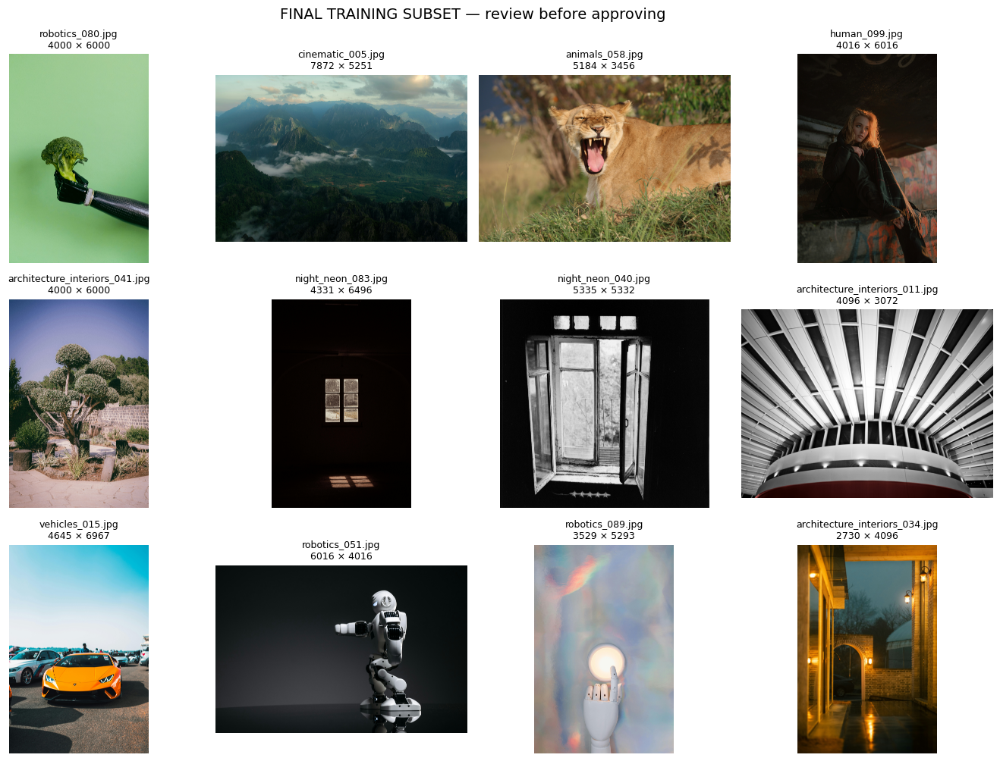

In [7]:
# filtering controls
APPROVED_FILENAMES = None      
EXCLUDED_FILENAMES = set()  

# drop images losing more than 25% of their frame to bucket cropping
MAX_ESTIMATED_CROP = 0.25     

# filter candidates
pool = audit.copy()
pool['filename'] = pool['image_path'].map(lambda p: Path(p).name)

pool = pool[~pool['filename'].isin(EXCLUDED_FILENAMES)]
if APPROVED_FILENAMES is not None:
    pool = pool[pool['filename'].isin(APPROVED_FILENAMES)]

pool = pool[pool['estimated_crop_fraction'] <= MAX_ESTIMATED_CROP].drop(columns=['filename'])

if pool.empty:
    raise RuntimeError("No images left after filtering. Relax MAX_ESTIMATED_CROP or check your filename lists.")

# round-robin across filename prefixes for balanced representation
target_total = min(MAX_TRAINING_CANDIDATES, len(pool))
category_buckets = {
    cat: group.sample(frac=1.0, random_state=SEED).to_dict('records')
    for cat, group in pool.groupby('category')
}

selected_rows = []
while len(selected_rows) < target_total:
    added_any = False
    for cat in sorted(category_buckets):
        if len(selected_rows) >= target_total:
            break
        if category_buckets[cat]:
            selected_rows.append(category_buckets[cat].pop())
            added_any = True
    if not added_any:
        break

selected = pd.DataFrame(selected_rows).sample(frac=1.0, random_state=SEED).reset_index(drop=True)

# here we split each category into training and holdout sets
train_splits, holdout_splits = [], []

for cat, group in selected.groupby('category'):
    shuffled = group.sample(frac=1.0, random_state=SEED)
    n_holdout = min(len(shuffled) - 1, max(1, round(len(shuffled) * HOLDOUT_FRACTION))) if len(shuffled) > 1 else 0
    
    holdout_splits.append(shuffled.iloc[:n_holdout])
    train_splits.append(shuffled.iloc[n_holdout:])

train_df = pd.concat(train_splits, ignore_index=True)
held_df = pd.concat(holdout_splits, ignore_index=True)

# Summary & visual check
print(f"Total selected: {len(selected)} | Training: {len(train_df)} | Holdout: {len(held_df)}")
print("\nTraining distribution by filename prefix:")
display(train_df['category'].value_counts().rename_axis('category').to_frame('train_images'))

contact_sheet(train_df, n=12, title='FINAL TRAINING SUBSET — review before approving')

### Stage Training & Holdout Files

Since `/kaggle/input` is read-only, this step copies the approved training and holdout pairs into writable working directories (`TRAIN_IMAGES` and `HOLDOUT_IMAGES`) without resizing or cropping them. 

If `ADD_STYLE_TRIGGER` is enabled (for this training it's disabled), the trigger word is prepended to the copied `.txt` captions automatically. A short folder hash is appended to each filename so files from different subfolders never overwrite each other.

In [8]:
APPROVE_STAGING = True

def clear_staged_directory(folder):
    """Remove previously staged images, captions, and cached latents."""
    allowed_exts = IMAGE_SUFFIXES | {'.txt', '.npz', '.npy'}
    for file_path in folder.iterdir():
        if file_path.is_file() and file_path.suffix.lower() in allowed_exts:
            file_path.unlink()


def copy_split_to_staging(df, dest_dir, split_label):
    """Copy images and formatted captions into the working directory."""
    staged_records = []

    for _, row in df.iterrows():
        src_img = Path(row['image_path'])

        # Hash the relative subfolder path to prevent filename collisions
        rel_folder = str(src_img.parent.relative_to(source)) if src_img.parent != source else '.'
        folder_hash = hashlib.sha256(rel_folder.encode('utf-8')).hexdigest()[:6]
        staged_stem = f"{src_img.stem}_{folder_hash}"

        dst_img = dest_dir / f"{staged_stem}{src_img.suffix.lower()}"
        dst_txt = dest_dir / f"{staged_stem}.txt"

        # Copy original image untouched
        shutil.copy2(src_img, dst_img)

        # Prepend style trigger word to caption if enabled and not already present
        caption = row['caption'].strip()
        if ADD_STYLE_TRIGGER and STYLE_TRIGGER.lower() not in caption.lower():
            caption = f"{STYLE_TRIGGER}, {caption}"

        dst_txt.write_text(caption + '\n', encoding='utf-8')

        staged_records.append({
            'split': split_label,
            'staged_image': str(dst_img),
            'staged_caption': str(dst_txt),
            'source_image': str(src_img),
            'source_caption': str(row['caption_file']),
            'category': row['category'],
            'width': int(row['width']),
            'height': int(row['height']),
            'approx_crop': float(row['estimated_crop_fraction']),
            'sha256': row['sha256'],
            'caption': caption,
        })

    return staged_records


if not APPROVE_STAGING:
    print("STAGING PAUSED: Review your training subset above, then set APPROVE_STAGING = True and re-run.")
else:
    # 1. Clean out any old files from previous runs
    clear_staged_directory(TRAIN_IMAGES)
    clear_staged_directory(HOLDOUT_IMAGES)

    # 2. Copy train and holdout splits into working storage
    staged_items = (
        copy_split_to_staging(train_df, TRAIN_IMAGES, 'train') +
        copy_split_to_staging(held_df, HOLDOUT_IMAGES, 'holdout')
    )

    # 3. Save manifest and run configuration metadata
    manifest = pd.DataFrame(staged_items)
    manifest.to_csv(ROOT / 'dataset_manifest.csv', index=False)

    selection_metadata = {
        'source': str(source),
        'seed': SEED,
        'training_images': len(train_df),
        'holdout_images': len(held_df),
        'max_candidates': MAX_TRAINING_CANDIDATES,
        'min_short_edge': MIN_SHORT_EDGE,
        'style_trigger': STYLE_TRIGGER if ADD_STYLE_TRIGGER else None,
        'subset_prefix_counts': train_df['category'].value_counts().to_dict(),
        'created_utc': datetime.now(timezone.utc).isoformat(),
    }
    (CONFIG_DIR / 'dataset_selection.json').write_text(
        json.dumps(selection_metadata, indent=2), encoding='utf-8'
    )

    print(f"Staged {len(train_df)} training pairs and {len(held_df)} holdout pairs.")
    print(f"Manifest saved to: {ROOT / 'dataset_manifest.csv'}")

Staged 556 training pairs and 62 holdout pairs.
Manifest saved to: /kaggle/working/sketch2future_lora/dataset_manifest.csv


### Checking Staged Dataset & Environment

Before downloading model weights or starting training, this cell verifies that `TRAIN_IMAGES` has matching, non-empty `.txt` captions for every image and confirms if Kaggle environment has a GPU and PyTorch **2.6+** (required by `sd-scripts v0.12.3`).

In [9]:
from packaging.version import Version

def validate_stage():
    imgs = sorted(p for p in TRAIN_IMAGES.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
    missing = [p.name for p in imgs if not p.with_suffix('.txt').is_file()]
    txts = sorted(p for p in TRAIN_IMAGES.iterdir() if p.is_file() and p.suffix.lower()=='.txt')
    print(f'Staged train images: {len(imgs)}, staged .txt captions: {len(txts)}')
    if missing: raise RuntimeError(f'Missing captions for: {missing[:10]}')
    if not imgs: raise RuntimeError('No staged training images. Set APPROVE_STAGING=True in previous cell.')
    if len(imgs) != len(txts): raise RuntimeError('Unmatched captions remain; investigate staged folder.')
    for p in imgs:
        if not p.with_suffix('.txt').read_text(encoding='utf-8').strip():
            raise RuntimeError('Blank caption: '+p.name)
    return len(imgs)

NUM_TRAINING_IMAGES = validate_stage()
if NUM_TRAINING_IMAGES < 40:
    print('WARNING: fewer than 40 training images. Risk of overfitting; this is best treated as a smoke test.')
print('PyTorch version:', torch.__version__)
if Version(torch.__version__.split('+')[0]) < Version('2.6.0'):
    raise RuntimeError('sd-scripts v0.12.3 needs PyTorch >=2.6.0. Use a compatible Kaggle GPU image or install a matching CUDA torch build deliberately (then restart kernel).')
print('Check passed for staged files and PyTorch.')

Staged train images: 556, staged .txt captions: 556
PyTorch version: 2.11.0+cu130
Check passed for staged files and PyTorch.


## Installing the trainer

Training is performed by the maintained `kohya-ss/sd-scripts` `train_network.py`. Unlike the default Diffusers text-to-image example, its dataset config supports **native same-stem `.txt` captions and aspect-ratio bucketing**. We pin release `v0.12.3` to improve reproducibility.

**Run both cells once in a fresh notebook.** Installing packages can update `transformers`, `diffusers`, etc.; if Kaggle warns that a kernel restart is required, restart and re-run the preceding cells. The trainer uses the GPU-enabled PyTorch already installed in Kaggle.

In [10]:
SD_SCRIPTS_DIR = Path('/kaggle/working/sd-scripts')
SD_SCRIPTS_TAG = 'v0.12.3'
if not (SD_SCRIPTS_DIR / 'train_network.py').exists():
    subprocess.run(['git','clone','--depth','1','--branch',SD_SCRIPTS_TAG,
                    'https://github.com/kohya-ss/sd-scripts.git', str(SD_SCRIPTS_DIR)], check=True)
print('Trainer tag:', SD_SCRIPTS_TAG)
print('Repository revision:', subprocess.check_output(['git','-C',str(SD_SCRIPTS_DIR),'rev-parse','HEAD'], text=True).strip())

Cloning into '/kaggle/working/sd-scripts'...


Trainer tag: v0.12.3
Repository revision: cb70b96858477e716a2096292ab8aab433277f38


Note: switching to 'cb70b96858477e716a2096292ab8aab433277f38'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false



**Note: DO NOT RUN after restart**

In [11]:
# The pinned release's requirements are installed in the notebook Python environment.
install_cmd = [sys.executable, '-m', 'pip', 'install', '-q', '-r', str(SD_SCRIPTS_DIR / 'requirements.txt')]
print('Installing sd-scripts requirements...')
subprocess.run(install_cmd, cwd=str(SD_SCRIPTS_DIR), check=True)
print('Done. If Kaggle asks to restart the session, restart and rerun cells above.')

Installing sd-scripts requirements...


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
bigframes 2.51.0 requires rich<14,>=12.4.4, but you have rich 14.1.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


Done. If Kaggle asks to restart the session, restart and rerun cells above.


In [12]:
pip install --upgrade "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 73.1 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.


## The LoRA training parameters

- **Base:** exactly the SD 1.5 model used in Approach 1.
- **Train:** LoRA **U-Net only** (not ControlNet, not CLIP text encoder).
- **Preserve composition:** aspect-ratio buckets with no upscaling where possible. Some slight cropping may still occur.
- **Memory:** FP16, batch size 1, gradient accumulation 4, gradient checkpointing, 8-bit AdamW, VAE latent caching, SDPA attention.
- **Checkpoints:** training is step-limited and outputs intermediate `.safetensors` for comparison.

`MAX_STEPS=450` is an initial trial, not a guarantee of convergence. Examine results at multiple checkpoints for overfitting or style degradation. `rank=16` is intentionally modest.

In [14]:
# Model & Checkpoint Naming
BASE_MODEL_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
CONTROLNET_ID = 'lllyasviel/control_v11p_sd15_scribble'  # Used only during inference
LORA_NAME = 'sketch2future_sd15_lora'

# LoRA Hyperparameters (tuned for approx. 560 training images from 623 total)
LORA_RANK = 32            
LORA_ALPHA = 16            # Half-rank alpha stabilizes training across 1,400+ steps
LEARNING_RATE = 1e-4
MAX_STEPS = 1400           # ~10 epochs for 560 images at effective batch size 4
SAVE_EVERY_STEPS = 350     # Saves checkpoints at 350, 700, 1050, and 1400 steps
GRAD_ACCUMULATION = 4
TRAIN_BATCH_SIZE = 1
RESOLUTION = 512

# the Kohya sd-scripts Dataset TOML
dataset_toml = f"""[general]
caption_extension = ".txt"
shuffle_caption = true
keep_tokens = {1 if ADD_STYLE_TRIGGER else 0}

[[datasets]]
resolution = [{RESOLUTION}, {RESOLUTION}]
batch_size = {TRAIN_BATCH_SIZE}
enable_bucket = true
bucket_no_upscale = true
bucket_reso_steps = 64
min_bucket_reso = 256
max_bucket_reso = 768

  [[datasets.subsets]]
  image_dir = "{TRAIN_IMAGES.as_posix()}"
  num_repeats = 1
"""

TOML_PATH = CONFIG_DIR / 'dataset_config.toml'
TOML_PATH.write_text(dataset_toml, encoding='utf-8')
print(dataset_toml)

# Save Run Metadata
run_spec = {
    'base_model': BASE_MODEL_ID,
    'controlnet_for_evaluation': CONTROLNET_ID,
    'trainer_repo': 'kohya-ss/sd-scripts',
    'trainer_tag': SD_SCRIPTS_TAG,
    'lora_rank': LORA_RANK,
    'lora_alpha': LORA_ALPHA,
    'learning_rate': LEARNING_RATE,
    'max_steps': MAX_STEPS,
    'batch_size': TRAIN_BATCH_SIZE,
    'gradient_accumulation': GRAD_ACCUMULATION,
    'resolution': RESOLUTION,
    'seed': SEED,
    'use_style_trigger': ADD_STYLE_TRIGGER,
    'style_trigger': STYLE_TRIGGER if ADD_STYLE_TRIGGER else None,
}
(CONFIG_DIR / 'training_settings.json').write_text(json.dumps(run_spec, indent=2), encoding='utf-8')

[general]
caption_extension = ".txt"
shuffle_caption = true
keep_tokens = 0

[[datasets]]
resolution = [512, 512]
batch_size = 1
enable_bucket = true
bucket_no_upscale = true
bucket_reso_steps = 64
min_bucket_reso = 256
max_bucket_reso = 768

  [[datasets.subsets]]
  image_dir = "/kaggle/working/sketch2future_lora/train_images"
  num_repeats = 1



432

## Building the LoRA Training Command

This cell constructs the exact `accelerate` command passed to Kohya's `train_network.py` and saves a copy to `train_command.json` for reproducibility.

In [15]:
RUN_TRAINING = True

# Build accelerate + sd-scripts training command
TRAIN_COMMAND = [
    sys.executable, '-m', 'accelerate.commands.launch',
    '--num_processes=1',
    '--num_machines=1',
    '--mixed_precision=fp16',
    '--num_cpu_threads_per_process=2',
    'train_network.py',

    # Base model, dataset config & output paths
    f'--pretrained_model_name_or_path={BASE_MODEL_ID}',
    f'--dataset_config={TOML_PATH}',
    f'--output_dir={MODEL_DIR}',
    f'--output_name={LORA_NAME}',
    '--save_model_as=safetensors',
    '--save_precision=fp16',

    # LoRA architecture (trains both UNet and Text Encoder)
    '--network_module=networks.lora',
    f'--network_dim={LORA_RANK}',
    f'--network_alpha={LORA_ALPHA}',
    f'--unet_lr={LEARNING_RATE}',
    f'--text_encoder_lr={LEARNING_RATE * 0.5}',

    # Optimizer & learning rate schedule
    '--optimizer_type=AdamW8bit',
    '--lr_scheduler=cosine',
    f'--lr_warmup_steps={min(100, MAX_STEPS // 10)}',
    f'--max_train_steps={MAX_STEPS}',
    f'--save_every_n_steps={SAVE_EVERY_STEPS}',
    f'--gradient_accumulation_steps={GRAD_ACCUMULATION}',
    '--max_grad_norm=1.0',

    # Memory & speed optimizations for Kaggle GPUs
    '--gradient_checkpointing',
    '--cache_latents',
    '--cache_latents_to_disk',
    '--sdpa',
    '--mixed_precision=fp16',
    f'--seed={SEED}',
]

print(f"Trainer directory : {SD_SCRIPTS_DIR}")
print(f"Output directory  : {MODEL_DIR}")
print("\nGenerated command:\n", ' '.join(TRAIN_COMMAND))

# Save exact command for reproducibility
(CONFIG_DIR / 'train_command.json').write_text(json.dumps(TRAIN_COMMAND, indent=2), encoding='utf-8')

Trainer directory : /kaggle/working/sd-scripts
Output directory  : /kaggle/working/sketch2future_lora/lora_weights

Generated command:
 /usr/bin/python3 -m accelerate.commands.launch --num_processes=1 --num_machines=1 --mixed_precision=fp16 --num_cpu_threads_per_process=2 train_network.py --pretrained_model_name_or_path=stable-diffusion-v1-5/stable-diffusion-v1-5 --dataset_config=/kaggle/working/sketch2future_lora/config/dataset_config.toml --output_dir=/kaggle/working/sketch2future_lora/lora_weights --output_name=sketch2future_sd15_lora --save_model_as=safetensors --save_precision=fp16 --network_module=networks.lora --network_dim=32 --network_alpha=16 --unet_lr=0.0001 --text_encoder_lr=5e-05 --optimizer_type=AdamW8bit --lr_scheduler=cosine --lr_warmup_steps=100 --max_train_steps=1400 --save_every_n_steps=350 --gradient_accumulation_steps=4 --max_grad_norm=1.0 --gradient_checkpointing --cache_latents --cache_latents_to_disk --sdpa --mixed_precision=fp16 --seed=42


1004

## Train the LoRA

In [16]:
if RUN_TRAINING:
    validate_stage()
    env = os.environ.copy()
    env['CUDA_VISIBLE_DEVICES'] = '0'      # Kaggle may provide 2 T4s; this training uses just the first
    env['TOKENIZERS_PARALLELISM'] = 'false'
    env['PYTHONUNBUFFERED'] = '1'
    log_file = LOG_DIR / 'lora_training.log'
    print('Starting LoRA training; log file:', log_file)
    with open(log_file, 'w', encoding='utf-8') as log:
        proc = subprocess.Popen(TRAIN_COMMAND, cwd=str(SD_SCRIPTS_DIR),
                                env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                text=True, bufsize=1)
        for line in proc.stdout:
            log.write(line)
            log.flush()
            print(line, end='')
        returncode = proc.wait()
    if returncode != 0:
        raise RuntimeError(f'Training returned exit code {returncode}. Review {log_file} for the exact error.')
    print('TRAINING COMPLETE. Check .safetensors files in:', MODEL_DIR)
else:
    print('DRY RUN ONLY. No training executed. Set RUN_TRAINING=True in the preceding cell when ready.')

Staged train images: 556, staged .txt captions: 556
Starting LoRA training; log file: /kaggle/working/sketch2future_lora/logs/lora_training.log
The following values were not passed to `accelerate launch` and had defaults used instead:
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/kaggle/working/sd-scripts/library/strategy_base.py:107: SyntaxWarning: invalid escape sequence '\('
  \( - literal character '('
/kaggle/working/sd-scripts/library/custom_train_functions.py:174: SyntaxWarning: invalid escape sequence '\('
  \( - literal character '('
/kaggle/working/sd-scripts/library/lpw_stable_diffusion.py:70: SyntaxWarning: invalid escape sequence '\('
  \( - literal character '('
2026-11-20 12:21:55 INFO     Using v1 tokenizer                strategy_sd.py:34
2026-11-20 12:21:56 I

## N. Review saved LoRA checkpoints and choose one

Do not choose a checkpoint solely because it has the largest step count. Later we can compare fixed prompts and sketches at several checkpoints. If no LoRA weights are present, the optional inference test will be skipped.

In [17]:
checkpoint_paths = sorted(MODEL_DIR.glob('*.safetensors'), key=lambda p: p.stat().st_mtime)
print('LoRA files:', len(checkpoint_paths))
for p in checkpoint_paths:
    print(f'  {p.name}  ({p.stat().st_size / 2**20:.1f} MiB)')

# If final training weight is saved, we select it; otherwise take last-written checkpoint.
final_candidate = MODEL_DIR / f'{LORA_NAME}.safetensors'
SELECTED_LORA_FILE = final_candidate if final_candidate.exists() else (checkpoint_paths[-1] if checkpoint_paths else None)
print('Selected LoRA:', SELECTED_LORA_FILE)

LoRA files: 5
  sketch2future_sd15_lora-step00000350.safetensors  (36.6 MiB)
  sketch2future_sd15_lora-step00000700.safetensors  (36.6 MiB)
  sketch2future_sd15_lora-step00001050.safetensors  (36.6 MiB)
  sketch2future_sd15_lora-step00001400.safetensors  (36.6 MiB)
  sketch2future_sd15_lora.safetensors  (36.6 MiB)
Selected LoRA: /kaggle/working/sketch2future_lora/lora_weights/sketch2future_sd15_lora.safetensors


## O. Optional test — use the **same sketch + prompt** as Approach 1

For a reproducible comparison, set `TEST_SKETCH_PATH` to an evaluation sketch (outside the LoRA training folder). Keep the prompt, negative prompt, seed, steps and ControlNet scale aligned with Approach 1. The example is a building only; **change the prompt to match your own sketch**.

The inference cell intentionally generates the *baseline and LoRA results in the same environment* and records LoRA scale. If the optional test fails to load community-format LoRA weights, share the exact traceback; compatibility depends on the installed Diffusers version. Do not claim a result improved without inspecting the pair.

Sketch downloaded: /kaggle/working/test_sketch.png


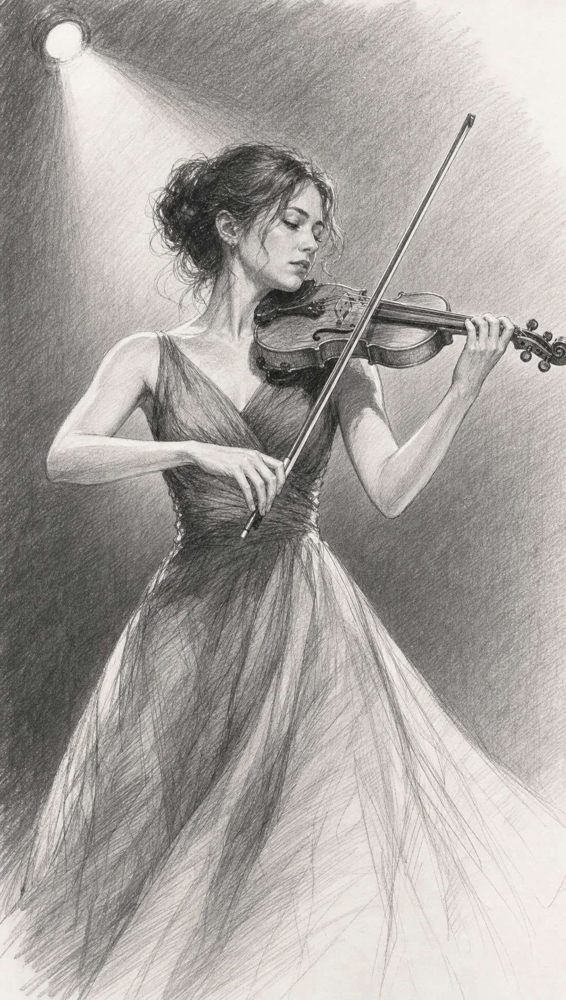

Optional comparison enabled: True
Evaluation prompt: lady playing violin on a stage with dramatic lighting, photorealistic, high detail


In [22]:
# Change this to a Kaggle input sketch location (NOT one of your LoRA training photographs).
# TEST_SKETCH_PATH = '/kaggle/input/datasets/gabswoch/building/building.jpg'  # e.g. '/kaggle/input/my-test-sketch/building_sketch.png'

import requests
from pathlib import Path
from io import BytesIO
from PIL import Image, ImageOps

SKETCH_URL = "https://external-cdn.morphic.com/website-production/assets/seo/images/seo/26-may/pencil-sketch-images/pencil-sketch-images-9x16-01.webp"

response = requests.get(SKETCH_URL, timeout=30)
response.raise_for_status()

sketch = Image.open(BytesIO(response.content))
sketch = ImageOps.exif_transpose(sketch).convert("RGB")

TEST_SKETCH_PATH = "/kaggle/working/test_sketch.png"
sketch.save(TEST_SKETCH_PATH)

print("Sketch downloaded:", TEST_SKETCH_PATH)
display(sketch)

TEST_PROMPT = 'lady playing violin on a stage with dramatic lighting, photorealistic, high detail'
TEST_NEGATIVE_PROMPT = 'low quality, blurry, distorted geometry, duplicate objects, unrealistic image'
INFERENCE_STEPS = 30
GUIDANCE_SCALE = 7.5
CONTROLNET_SCALE = 1.0
LORA_SCALE = 0.7
TEST_SEED = 42

EVAL_PROMPT = (STYLE_TRIGGER + ', ' + TEST_PROMPT) if ADD_STYLE_TRIGGER else TEST_PROMPT
RUN_COMPARISON = TEST_SKETCH_PATH is not None and SELECTED_LORA_FILE is not None
print('Optional comparison enabled:', RUN_COMPARISON)
print('Evaluation prompt:', EVAL_PROMPT)

config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Loaded LoRA (sketch2future_sd15_lora.safetensors): 576 UNet keys active


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

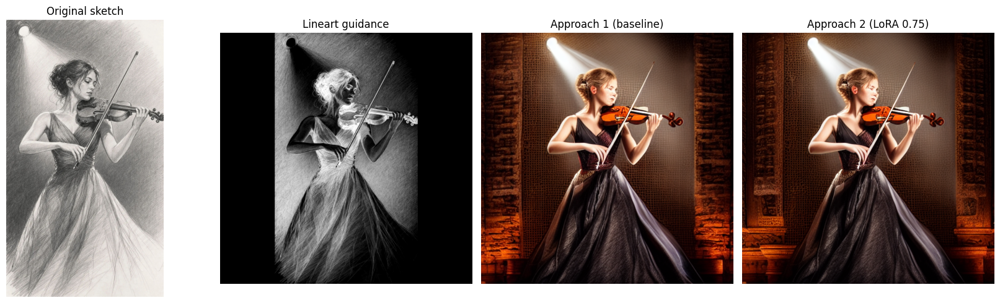

In [24]:
if RUN_COMPARISON:
    from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler
    from safetensors.torch import load_file
    import cv2
    from PIL import Image, ImageOps

    # Override to Lineart ControlNet & balanced scales for pencil sketches
    CONTROLNET_ID = 'lllyasviel/control_v11p_sd15_lineart'
    CONTROLNET_SCALE = 0.85
    LORA_SCALE = 0.75

    def sketch_to_lineart(im, target=512):
        """Convert a pencil sketch into clean white-on-black lineart without harsh thresholding."""
        contained = ImageOps.contain(im.convert('RGB'), (target, target))
        canvas = Image.new('RGB', (target, target), 'white')
        canvas.paste(contained, ((target - contained.width) // 2, (target - contained.height) // 2))

        gray = cv2.cvtColor(np.asarray(canvas), cv2.COLOR_RGB2GRAY)
        # Invert light paper background so strokes become white lines on a black background
        if np.median(gray) >= 128:
            gray = 255 - gray

        # Suppress faint paper grain while keeping soft pencil shading intact
        gray = np.clip((gray.astype(np.float32) - 25.0) * 1.35, 0, 255).astype(np.uint8)
        return Image.fromarray(gray).convert('RGB')

    gc.collect()
    torch.cuda.empty_cache()

    with Image.open(TEST_SKETCH_PATH) as im:
        sketch = ImageOps.exif_transpose(im).convert('RGB')
    lineart = sketch_to_lineart(sketch)
    lineart.save(PREVIEWS_DIR / 'test_controlnet_lineart.png')

    controlnet = ControlNetModel.from_pretrained(CONTROLNET_ID, torch_dtype=torch.float16, use_safetensors=True)
    pipe = StableDiffusionControlNetPipeline.from_pretrained(
        BASE_MODEL_ID, controlnet=controlnet, torch_dtype=torch.float16, use_safetensors=True
    )
    pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
    pipe = pipe.to('cuda:0')
    pipe.vae.enable_slicing()

    def generate_reference():
        generator = torch.Generator(device='cuda:0').manual_seed(TEST_SEED)
        return pipe(
            prompt=EVAL_PROMPT,
            negative_prompt=TEST_NEGATIVE_PROMPT,
            image=lineart,
            height=512,
            width=512,
            num_inference_steps=INFERENCE_STEPS,
            guidance_scale=GUIDANCE_SCALE,
            controlnet_conditioning_scale=CONTROLNET_SCALE,
            generator=generator,
            num_images_per_prompt=1,
        ).images[0]

    # 1. Generate the baseline (ControlNet Lineart + Base SD 1.5 without LoRA)
    baseline = generate_reference()
    baseline.save(PREVIEWS_DIR / 'comparison_baseline.png')

    # 2. Load UNet LoRA weights cleanly (avoids diffusers/peft text_encoder IndexError)
    lora_state_dict = load_file(str(SELECTED_LORA_FILE))
    unet_only_dict = {k: v for k, v in lora_state_dict.items() if k.startswith('lora_unet_')}
    print(f"Loaded LoRA ({SELECTED_LORA_FILE.name}): {len(unet_only_dict)} UNet keys active")

    pipe.load_lora_weights(unet_only_dict, adapter_name='sketch2future')
    pipe.set_adapters(['sketch2future'], adapter_weights=[LORA_SCALE])

    # 3. Generate LoRA result
    lora_result = generate_reference()
    lora_result.save(PREVIEWS_DIR / 'comparison_lora.png')

    # 4. Plot 4-panel side-by-side comparison
    fig, axes = plt.subplots(1, 4, figsize=(17, 5))
    for ax, im, title in zip(
        axes,
        [sketch, lineart, baseline, lora_result],
        ['Original sketch', 'Lineart guidance', 'Approach 1 (baseline)', f'Approach 2 (LoRA {LORA_SCALE})'],
    ):
        ax.imshow(im)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(PREVIEWS_DIR / 'lora_baseline_comparison.png', dpi=160, bbox_inches='tight')
    plt.show()

    comparison_metadata = dict(
        base_model=BASE_MODEL_ID,
        controlnet=CONTROLNET_ID,
        lora_weights=str(SELECTED_LORA_FILE),
        lora_scale=LORA_SCALE,
        sketch=str(TEST_SKETCH_PATH),
        prompt=EVAL_PROMPT,
        negative_prompt=TEST_NEGATIVE_PROMPT,
        seed=TEST_SEED,
        steps=INFERENCE_STEPS,
        guidance_scale=GUIDANCE_SCALE,
        controlnet_scale=CONTROLNET_SCALE,
        scheduler='UniPCMultistepScheduler',
    )
    (PREVIEWS_DIR / 'comparison_metadata.json').write_text(json.dumps(comparison_metadata, indent=2), encoding='utf-8')

    del pipe, controlnet
    gc.collect()
    torch.cuda.empty_cache()
else:
    print('Skipping optional inference: provide TEST_SKETCH_PATH and ensure a LoRA .safetensors exists.')

## Export reproducibility artifacts and LoRA weights

In [25]:
OUT_ZIP = Path('/kaggle/working/Sketch2Future_LoRA_Training_Artifacts.zip')
with zipfile.ZipFile(OUT_ZIP, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for folder in [CONFIG_DIR, LOG_DIR, MODEL_DIR, PREVIEWS_DIR]:
        for p in sorted(folder.rglob('*')):
            if p.is_file():
                z.write(p, arcname=str(p.relative_to(ROOT)))
    for fname in ['dataset_manifest.csv','eligible_audit.csv','rejected_audit.csv']:
        p=ROOT/fname
        if p.exists(): z.write(p, arcname=fname)
print('Reproducibility bundle:', OUT_ZIP)
print('Archive size (MiB):', round(OUT_ZIP.stat().st_size/2**20,1))
print('Weights folder:', MODEL_DIR)

Reproducibility bundle: /kaggle/working/Sketch2Future_LoRA_Training_Artifacts.zip
Archive size (MiB): 169.4
Weights folder: /kaggle/working/sketch2future_lora/lora_weights
